<a href="https://colab.research.google.com/github/CefasRepRes/shipwreck-oil-detection-colab/blob/main/Cefas_Segment_every_grain_colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Cloud Based Analysis of Cobbles from Seabed Imagery using SegmentEveryGrain**


---


This is a workflow on how to use the SegmentEveryGrain with Google Colab, note this is for demonstration only and to run large datasets specialised computer resource will be required.

This work is based upon https://github.com/zsylvester/segmenteverygrain

with adaptions based on their example workbook
https://github.com/zsylvester/segmenteverygrain/blob/main/notebooks/Segment_every_grain_colab.ipynb

Sylvester, Z., Stockli, D. F., Howes, N., Roberts, K., Malkowski, M. A., Poros, Z., Martindale, R. C., & Bai, W. (2025). Segmenteverygrain: A Python module for segmentation of grains in images. Journal of Open Source Software, 10(112), 7953. https://doi.org/10.21105/joss.07953


---



Project funded under EMODnet Geology.

Created By Hayden Close (Cefas)
hayden.close@cefas.gov.uk

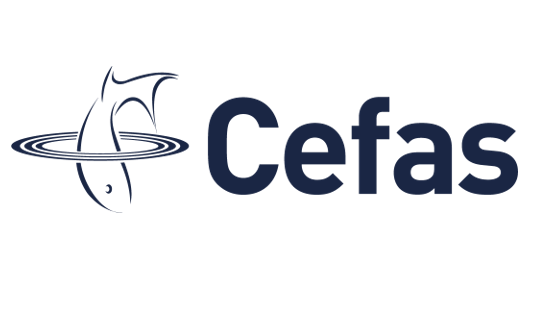

# **1. Install and import packages**


## 1.1 Set up interactive figure backend in Colab

Note the runtime (environment) will 'crash' that is normal as we ask it to restart so can ignore the message that pops up like:
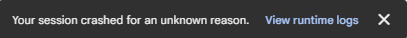

In [ ]:
# this is needed to make figures in Colab interactive
!pip install ipympl
exit(0) # this restarts the runtime after installing ipympl -- otherwise you get an error when switching the matplotlib backend to ipympl

Please wait for the runtime to restart before continuing else sometimes wont restart. Look in top right hand corner.

Runtime = restarting
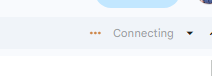






green tick = succesfully started 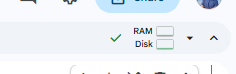

## **1.2 Install the other dependencies and download example imagery**

The below code downloads the CefasCobblesTools.ipynb so that we can call the functions from that script and keep this one tidy. It will install all the requirements needed in one go and downloads the example imagery to your content in your google drive, you can upload you own now if you wish.

Grains are supposed to be well defined in the image; e.g., if a grain consists of only a few pxiels, it is unlikely to be detected.

The segmentation can take a few minutes even for medium-sized images, so do not start with large images (downsample them if necessary).

For the examplar seabed  images,
 i have downsized from 5184 by 3456 to 2250 by 1500 pixels,
This enables the model to run in under 5 mins compared to ~1 hour on this platform.

Does mean you do loose some grain outlines but minimal overall impact.


In [ ]:
!wget -O CefasCobblesTools.ipynb https://raw.githubusercontent.com/CefasRepRes/shipwreck-oil-detection-colab/main/CefasCobblesTools.ipynb
%run /content/CefasCobblesTools.ipynb
install_requirements()

## **2.2 Connect to google drive**
First of all connect your google drive account with colab so you can store inputs such as wreck locations and even scripts with functions in.


In [ ]:
import google.colab.drive
google.colab.drive.mount('/content/drive', force_remount=True)

# **3. Run segmentation model**
The code below runs the segmentation.

No need to change the parameters here, but if you need to the dbs_max_dist can be tweaked with:


*   **Smaller value** causing nearby candidates to be less readily clustered together
*   **Larger value** allowing candidates to be farther apart and still be treated as belonging to the same cluster/grain.



Additionally, the min area can be changed with currently 150 pixels the minimum to form an object.

In [ ]:
Select_image()

In [ ]:
%%time
Run_segmentation()

## **3.1 Save the segmented images**

Saves the output as a .pkl file. This then can be used later to interact or plot the polygons without running the segmentation again.

In [ ]:
save_segmented_outputs()

# **4. Interactive editing of segmentation results**

**Note:** Interactive editing in Colab may be slower than in a local Jupyter notebook due to network latency.

Convert the polygons to Grain objects and use the interactive `GrainPlot` interface, make sure to click only once.

**Mouse controls:**
- **Left-click** on existing grain: Select/unselect
- **Left-click** in grain-free area: Instant grain creation
- **Alt + Left-click**: Multi-prompt grain creation
- **Alt + Right-click**: Background prompt for multi-prompt creation
- **Shift + drag**: Draw scale bar for unit conversion
- **Ctrl** (hold): Temporarily hide grain masks

**Keyboard controls:**
- **d**: Delete selected grains
- **m**: Merge selected grains
- **z**: Undo last created grain
- **Esc**: Clear selection and prompts
You only need to run this cell if you want to interactively edit the segmentation results and/or if you want to draw a scale bar (i.e. lasers)

In [ ]:
interactive_cleaning()

## **4.1 End interactive session and save**
Run this cell when you are done with interactive editing to retrieve the updated grains and deactivate the interface:

In [ ]:
# Retrieve updated grains and deactivate interactive mode
grains = plot.get_grains()
plot.deactivate()

# **5. Plot and export the grain size distribution**
🔵 Blue = major axis length, the longer dimension of each grain.
🟠 Orange = minor axis length, the shorter dimension of each grain

Coloured bars = number of grains within each size bin

Curved line = cumulative proportion of grains up to that size

In [ ]:
grain_size_distribution()

## **5.2 Automated cleaning solution**
The plots shows all those grains idenitfied > threshold chosen above (default 0.5) and seperate plot showing those removed, therefore easy to visual changes to the threshold.

In [ ]:
Plot_Auto_clean()

## **5.3 Export the data to your google drive**
Two CSVs are produced:



*   'image name'_grain_measurements.csv - this has each individual grains statistics
*   'image name'_grain_summary.csv - this as the statistics at the image level i.e. mean area (see table below)


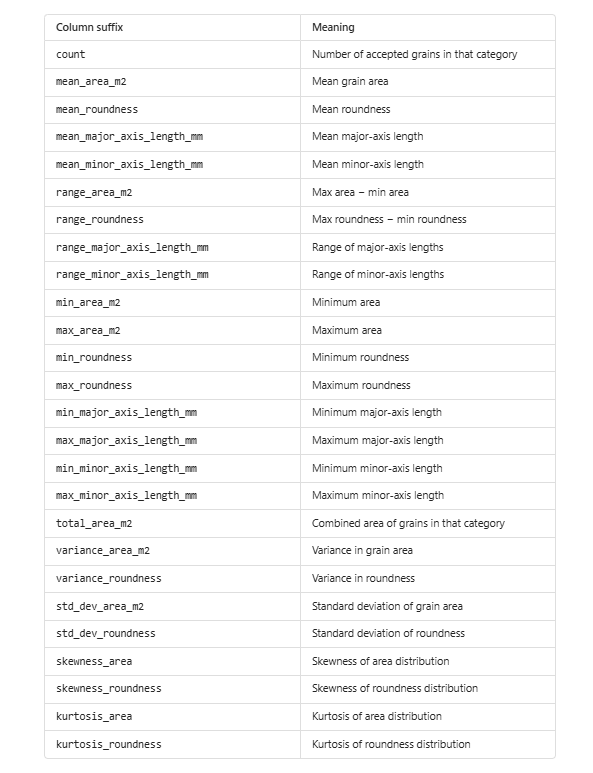

In [ ]:
Extract_grain_data(labels, image, grains, fname, pixel_length_m, Roundness_Thresh)

Please have a go with other example images or even upload your own
